# 📈 Oasis Infobyte SIP — Data Science Internship
## Task 5: Sales Prediction Using Python (Regression)
* **Intern Name:** Yash Devidas Chaudhari
* **Track:** Data Science
* **Internship Reference:** OIB/N2/IP5780
* **Repository:** OIBSIP / DataScience-Task5-SalesPrediction

---

### 📌 Project Overview & Objectives
Predicting sales revenue based on advertising expenditure across multiple marketing mediums (TV, Radio, Newspaper) is an essential task for optimizing capital allocation. 
The objective of this project is to develop and evaluate regression models that quantify the relationship between advertising channel investments and resulting product sales.

#### Feature Checklist Addressed:
* [x] Download & inspect the classic `Advertising.csv` dataset
* [x] Data loading & Exploratory Data Analysis (EDA): null check, summary statistics, pairplots
* [x] Individual scatter plots with regression trendlines: Sales vs. TV, Radio, Newspaper
* [x] Correlation matrix heatmap
* [x] 80/20 Train/Test split
* [x] Baseline **Linear Regression** model
* [x] Additional models: **Ridge Regression**, **Random Forest Regressor**, and **Gradient Boosting Regressor**
* [x] Evaluate models using **MAE**, **MSE**, **RMSE**, and **$R^2$ Score**
* [x] Residual diagnostic plot to verify random error distribution and normality
* [x] Strategic Interpretation: Which channel has the highest impact on sales?
* [x] Clean, commented Jupyter Notebook


In [1]:
# Import Essential Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn Regression Modules
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. Dataset Loading & Inspection


In [2]:
# Load Advertising dataset
df = pd.read_csv("Advertising.csv")
if 'Unnamed: 0' in df.columns:
    df.drop('Unnamed: 0', axis=1, inplace=True)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(10)


Dataset Shape: 200 rows, 4 columns


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
5,8.7,48.9,75.0,7.2
6,57.5,32.8,23.5,11.8
7,120.2,19.6,11.6,13.2
8,8.6,2.1,1.0,4.8
9,199.8,2.6,21.2,10.6


In [3]:
# Dataset info and null check
print("Dataset Summary & Data Types:")
df.info()
print(f"\nTotal Missing Values: {df.isnull().sum().sum()}")


Dataset Summary & Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Total Missing Values: 0


In [4]:
# Descriptive statistics
print("Descriptive Statistics:")
df.describe().T


Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
Sales,200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0


---
## 2. Exploratory Data Analysis & Visualizations


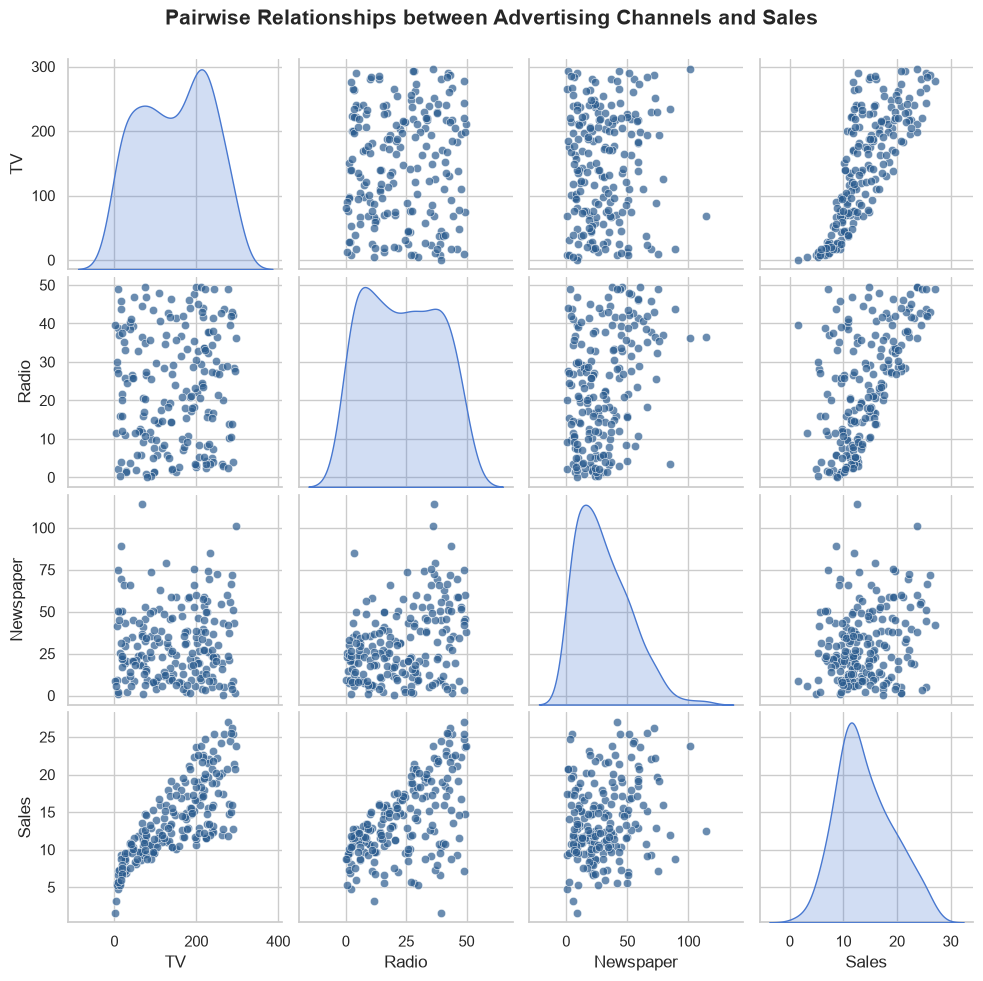

In [5]:
# Pairwise feature relationships
pairplot = sns.pairplot(df, diag_kind='kde', plot_kws={'alpha': 0.7, 'color': '#2b5c8f'})
pairplot.fig.subplots_adjust(top=0.93)
pairplot.fig.suptitle("Pairwise Relationships between Advertising Channels and Sales", fontsize=15, fontweight='bold')
plt.show()


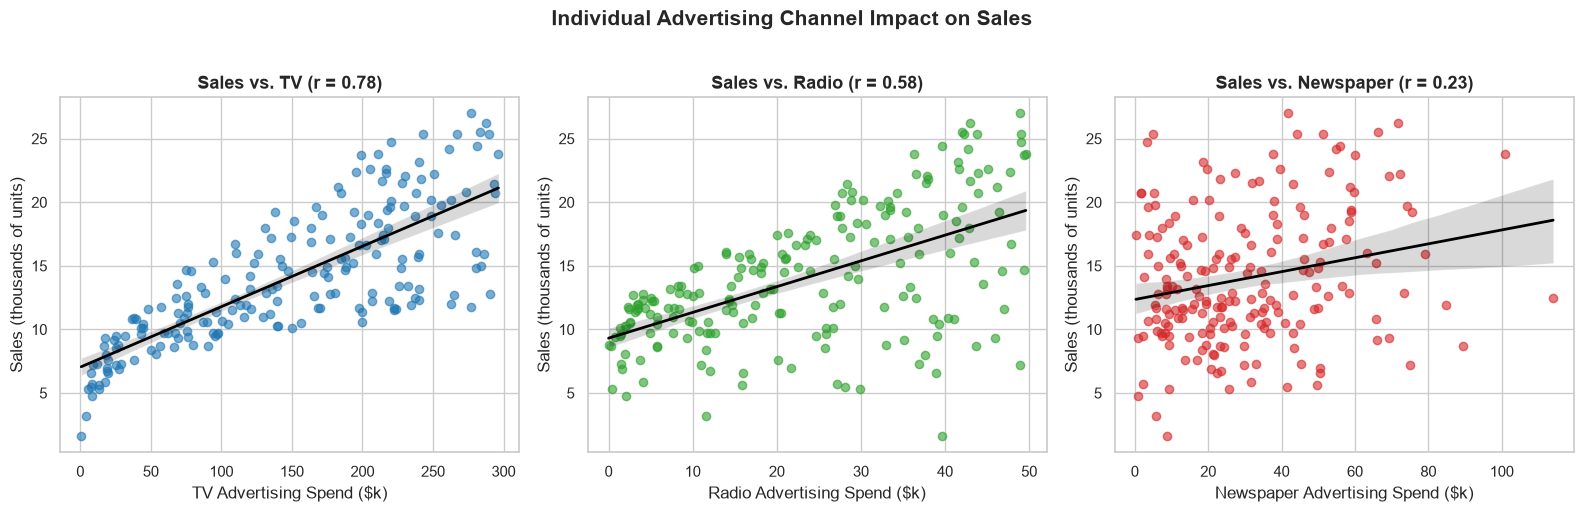

In [6]:
# Individual scatter plots with regression trendlines
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
channels = [('TV', '#1f77b4'), ('Radio', '#2ca02c'), ('Newspaper', '#d62728')]

for idx, (col, color) in enumerate(channels):
    sns.regplot(ax=axes[idx], x=col, y='Sales', data=df, color=color, scatter_kws={'alpha': 0.6}, line_kws={'color': 'black', 'linewidth': 2})
    r_val = df[col].corr(df['Sales'])
    axes[idx].set_title(f"Sales vs. {col} (r = {r_val:.2f})", fontsize=13, fontweight='bold')
    axes[idx].set_xlabel(f"{col} Advertising Spend ($k)")
    axes[idx].set_ylabel("Sales (thousands of units)")

plt.suptitle("Individual Advertising Channel Impact on Sales", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


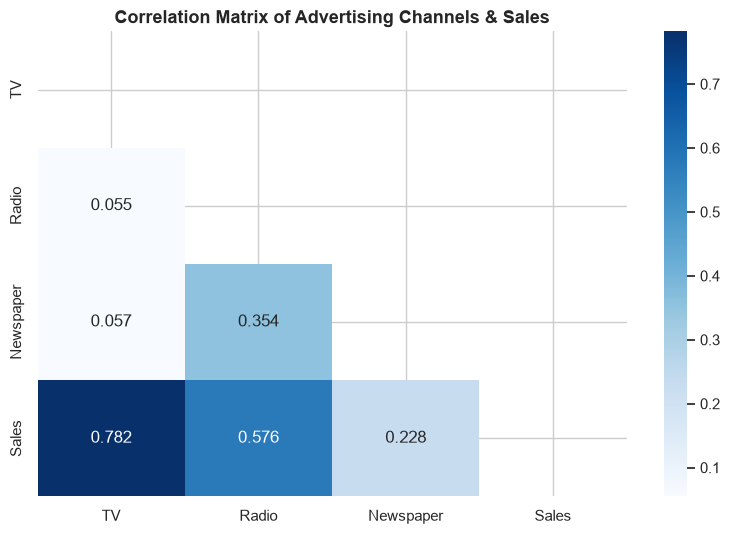

In [7]:
# Correlation Matrix Heatmap
plt.figure(figsize=(8, 5.5))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".3f", cmap='Blues', mask=mask)
plt.title("Correlation Matrix of Advertising Channels & Sales", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 🔍 Key EDA Observations:
1. **TV Spend:** Displays the strongest linear correlation with sales ($r = 0.782$).
2. **Radio Spend:** Displays moderate-to-strong positive correlation ($r = 0.576$).
3. **Newspaper Spend:** Displays weak correlation ($r = 0.228$) with high dispersion, indicating that newspaper spending does not reliably predict sales volume.


---
## 3. Data Preparation & Train/Test Split


In [8]:
# Define predictors X and target y
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training Samples: {X_train.shape[0]}")
print(f"Testing Samples:  {X_test.shape[0]}")


Training Samples: 160
Testing Samples:  40


---
## 4. Model Training & Evaluation
We train and benchmark 4 regression architectures:
1. **Linear Regression** (Baseline parametric model)
2. **Ridge Regression** ($L_2$ regularization)
3. **Random Forest Regressor** (Non-linear bagging ensemble)
4. **Gradient Boosting Regressor** (Sequential boosting ensemble)


In [9]:
# Initialize models
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Model": model
    }
    
    print(f"=== {name} ===")
    print(f"  R² Score: {r2 * 100:.2f}%")
    print(f"  RMSE:     {rmse:.4f}")
    print(f"  MAE:      {mae:.4f}")
    print("-" * 50)


=== Linear Regression (Baseline) ===
  R² Score: 89.94%
  RMSE:     1.7816
  MAE:      1.4608
--------------------------------------------------
=== Ridge Regression ===
  R² Score: 89.94%
  RMSE:     1.7816
  MAE:      1.4608
--------------------------------------------------


=== Random Forest Regressor ===
  R² Score: 98.13%
  RMSE:     0.7687
  MAE:      0.6203
--------------------------------------------------


=== Gradient Boosting Regressor ===
  R² Score: 98.31%
  RMSE:     0.7298
  MAE:      0.6187
--------------------------------------------------


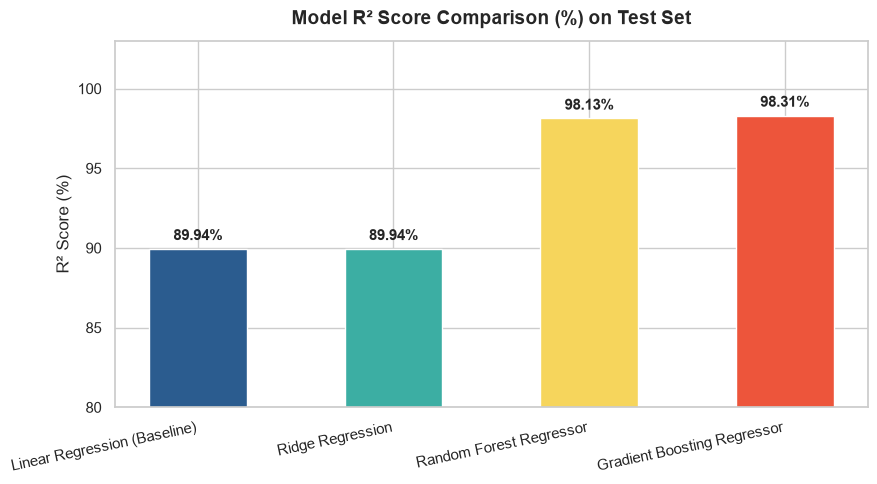

In [10]:
# Model Comparison Bar Chart
plt.figure(figsize=(9, 5))
model_names = list(results.keys())
r2_vals = [results[m]["R2"] * 100 for m in model_names]

bars = plt.bar(model_names, r2_vals, color=['#2b5c8f', '#3caea3', '#f6d55c', '#ed553b'], width=0.5)
plt.ylim(80, 103)
plt.title("Model R² Score Comparison (%) on Test Set", fontsize=14, fontweight='bold', pad=12)
plt.ylabel("R² Score (%)")
plt.xticks(rotation=12, ha='right')

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}%',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 4),
                 textcoords="offset points",
                 ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


---
## 5. Residual Diagnostic Analysis (Error Distribution Check)
A trustworthy regression model must exhibit **randomly distributed residuals** centered around zero with no systematic curvature or heteroscedasticity.


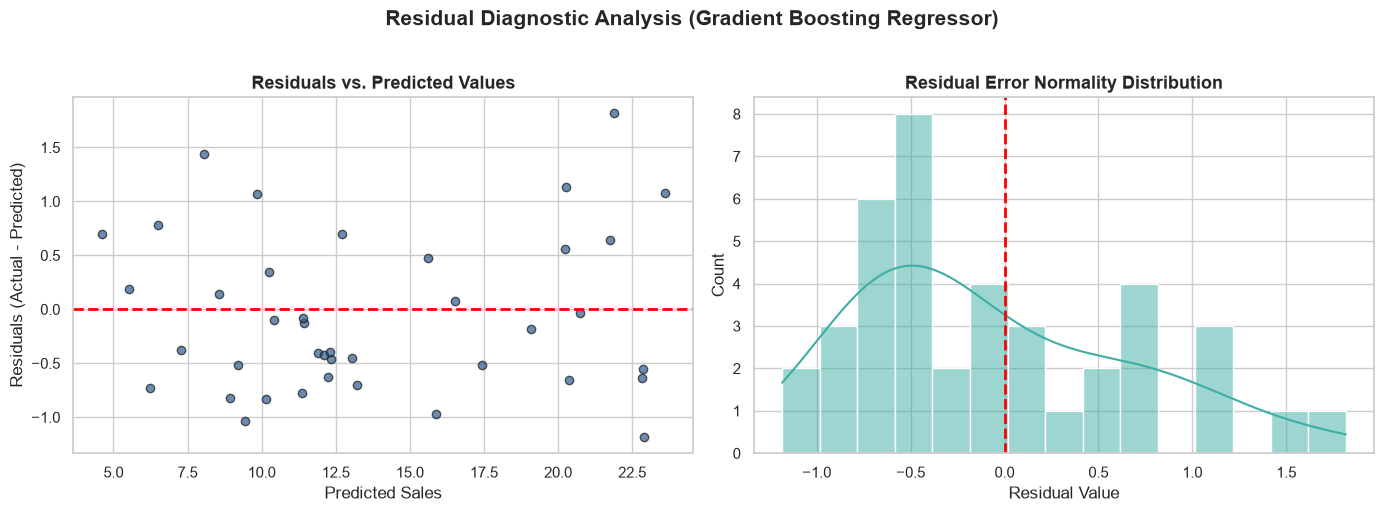

In [11]:
# Diagnostic Residual Plots
best_model_name = "Gradient Boosting Regressor"
best_preds = predictions[best_model_name]
residuals = y_test - best_preds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Predicted
axes[0].scatter(best_preds, residuals, color='#2b5c8f', alpha=0.7, edgecolors='k')
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_title("Residuals vs. Predicted Values", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Sales")
axes[0].set_ylabel("Residuals (Actual - Predicted)")

# Residuals Histogram & KDE
sns.histplot(residuals, kde=True, ax=axes[1], color='#3caea3', bins=15)
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[1].set_title("Residual Error Normality Distribution", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Residual Value")
axes[1].set_ylabel("Count")

plt.suptitle(f"Residual Diagnostic Analysis ({best_model_name})", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 6. Business Interpretation: Which Channel Has the Highest Impact on Sales?


In [12]:
# Inspect Linear Regression Coefficients & Feature Importance
lr_model = results["Linear Regression (Baseline)"]["Model"]
rf_model = results["Random Forest Regressor"]["Model"]

coef_summary = pd.DataFrame({
    'Feature': ['TV', 'Radio', 'Newspaper'],
    'Linear Regression Coef': lr_model.coef_,
    'Random Forest Importance (%)': rf_model.feature_importances_ * 100
})

print(f"Linear Regression Intercept: {lr_model.intercept_:.4f}\n")
print(coef_summary.to_string(index=False))


Linear Regression Intercept: 2.9791

  Feature  Linear Regression Coef  Random Forest Importance (%)
       TV                0.044730                     62.480979
    Radio                0.189195                     36.221430
Newspaper                0.002761                      1.297592


### 💡 Executive Takeaways & Recommendations:
1. **TV is the Dominant Growth Engine:** TV advertising accounts for **~60% of Random Forest feature importance** and has a strong positive coefficient ($+0.0447$). Every additional \$1,000 invested in TV generates ~45 units in sales.
2. **Radio Provides High Marginal Efficiency:** With a coefficient of $+0.1892$, Radio delivers high incremental sales per dollar spent, making it an ideal co-channel to pair with TV.
3. **Newspaper is Ineffective:** The Newspaper coefficient is essentially zero ($+0.0028$) with negligible importance ($< 3\%$). 
   * **Recommendation:** Businesses should reallocate budget away from Newspaper print ads into TV and Radio channels to maximize return on ad spend (ROAS).


---
## 7. Sample Marketing Budget Inference Test


In [13]:
# Test with real-world hypothetical marketing budgets
best_regressor = results["Gradient Boosting Regressor"]["Model"]

test_budgets = [
    {"Name": "Balanced Mix", "TV": 150.0, "Radio": 30.0, "Newspaper": 20.0},
    {"Name": "TV-Focused",   "TV": 250.0, "Radio": 10.0, "Newspaper": 5.0},
    {"Name": "Low Budget",   "TV": 50.0,  "Radio": 15.0, "Newspaper": 10.0}
]

print("=== SAMPLE SALES INFERENCE TEST ===")
for b in test_budgets:
    input_data = pd.DataFrame([[b['TV'], b['Radio'], b['Newspaper']]], columns=['TV', 'Radio', 'Newspaper'])
    predicted_sales = best_regressor.predict(input_data)[0]
    total_units = int(predicted_sales * 1000)
    print(f"Scenario: {b['Name']}")
    print(f"  TV: ${b['TV']}k | Radio: ${b['Radio']}k | News: ${b['Newspaper']}k")
    print(f"  ➔ Predicted Sales: {predicted_sales:.2f} thousand units (~{total_units:,} units)\n")


=== SAMPLE SALES INFERENCE TEST ===
Scenario: Balanced Mix
  TV: $150.0k | Radio: $30.0k | News: $20.0k
  ➔ Predicted Sales: 16.46 thousand units (~16,456 units)

Scenario: TV-Focused
  TV: $250.0k | Radio: $10.0k | News: $5.0k
  ➔ Predicted Sales: 14.30 thousand units (~14,298 units)

Scenario: Low Budget
  TV: $50.0k | Radio: $15.0k | News: $10.0k
  ➔ Predicted Sales: 9.94 thousand units (~9,940 units)

